# 5. Positional Information

Transformers use **attention instead of recurrence** to process tokens.

However, this creates an important problem:

> **How does the Transformer know the order of the tokens?**



---

## 5.1 Why Is Position Information Required?

Consider these two sentences:

```text
The dog bites the man.
```

and:

```text
The man bites the dog.
```

They contain exactly the same words, but the meaning is different because the **order of the words is different**.

```text
The → dog → bites → the → man
```

is different from:

```text
The → man → bites → the → dog
```

Therefore, a Transformer needs to know not only:

> **Which tokens are present?**

but also:

> **Where is each token located in the sequence?**

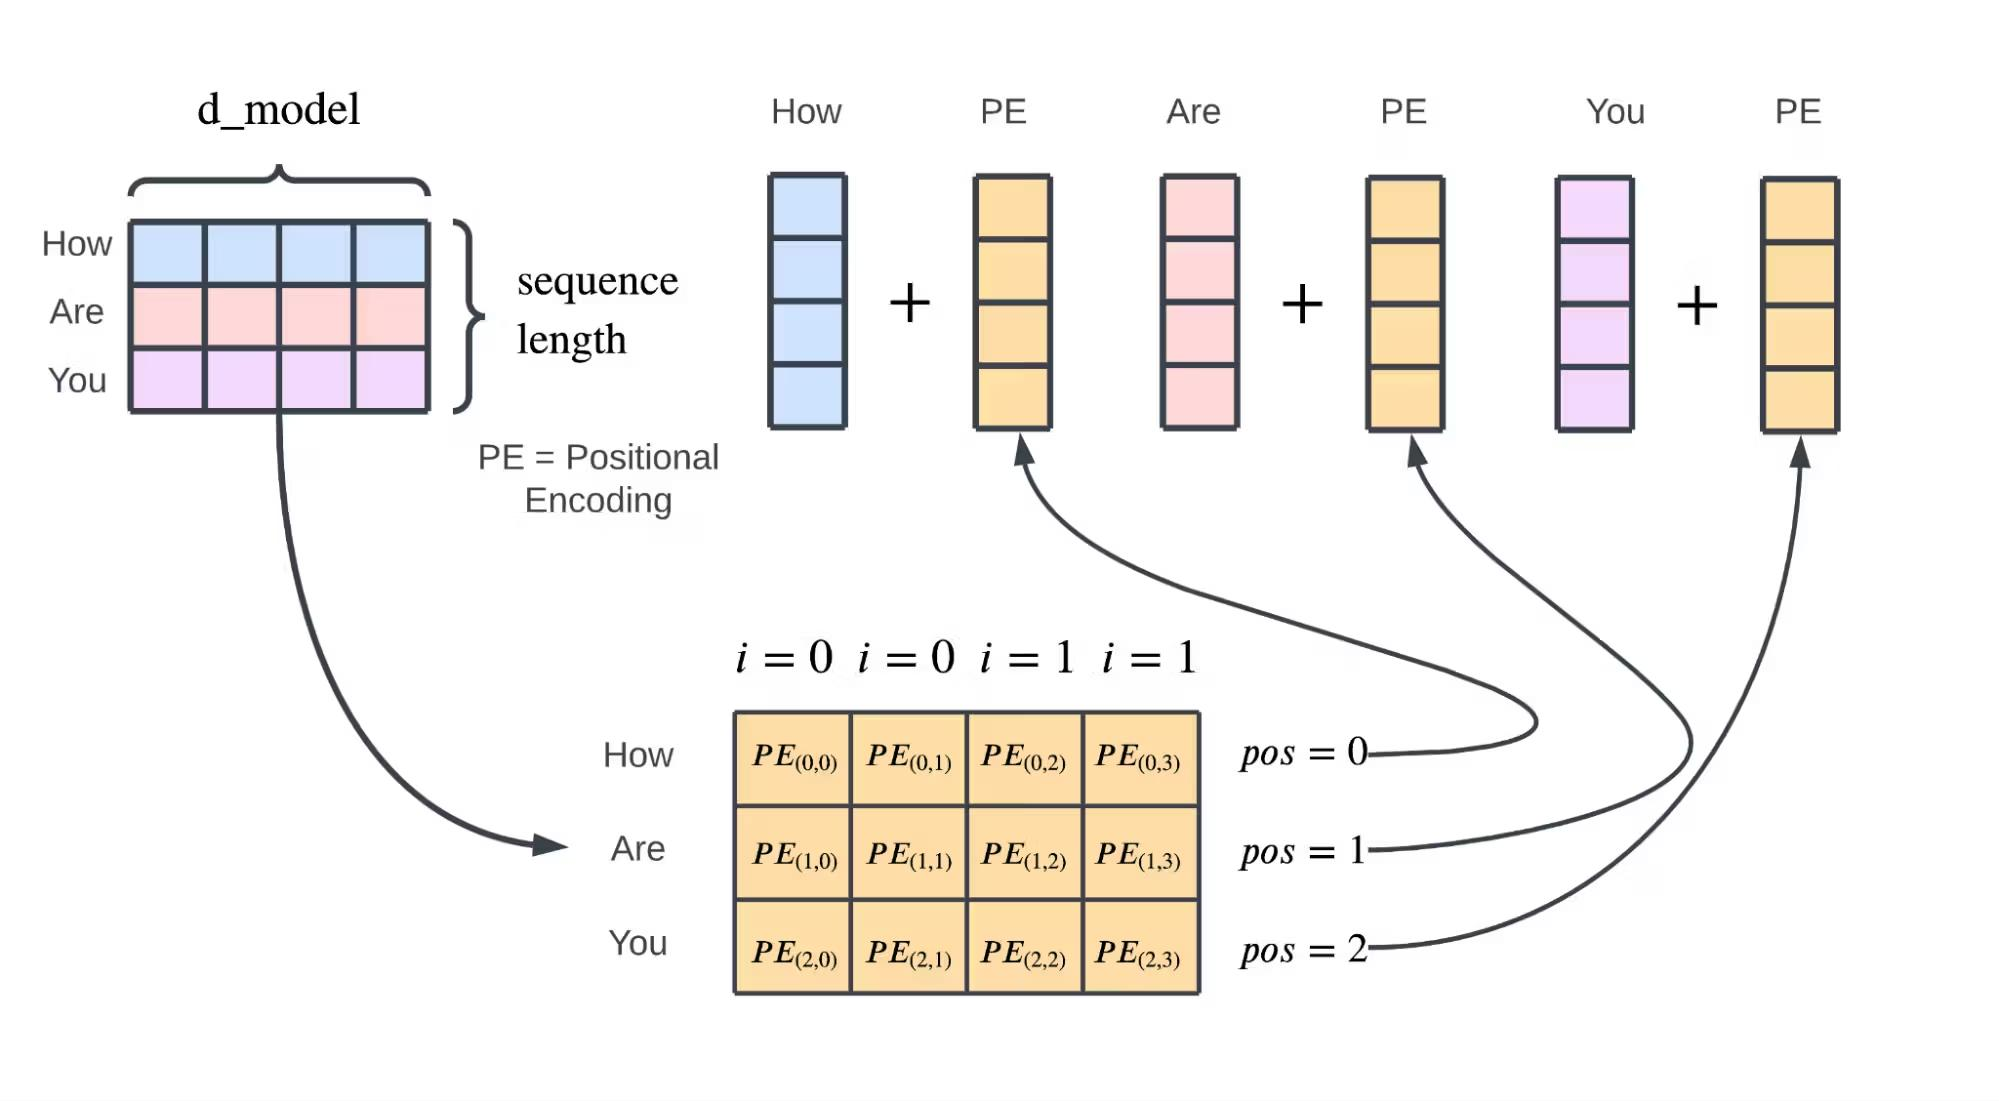

---

## 5.2 Why Attention Alone Is Not Enough

Self-attention operates on relationships between token representations.

Without positional information, the model does not inherently have a representation of:

```text
1st token
2nd token
3rd token
...
```

The Transformer architecture does not use recurrence to naturally encode sequence order.

Recall:

```text
RNN

x₁ → x₂ → x₃ → x₄
 ↓    ↓    ↓    ↓
Sequential structure
```

The sequence order is naturally associated with the recurrent computation.

But a Transformer performs attention over token representations:

```text
Transformer

x₁   x₂   x₃   x₄
 \   |   / \   |
    Attention
```

Therefore, positional information must be provided explicitly.

---

# 5.3 Token Embedding + Position

A Transformer typically combines the token representation with information about its position.

Conceptually:

```text
Token
  ↓
Token Embedding ─────┐
                     ├──► Transformer Input
Position ────────────┘
```

For a sentence:

```text
"The cat sat"
```

we can represent it as:

```text
Token       Position

"The"   →      1
"cat"   →      2
"sat"   →      3
```

The model therefore receives both:

- **what the token is**
- **where the token occurs**

---

## 5.4 Positional Encoding

One approach used in the original Transformer is **sinusoidal positional encoding**.

The positional encoding is added to the token embeddings:

$$
X = E + P
$$

where:

- \(E\) = token embeddings
- \(P\) = positional encodings
- \(X\) = input to the Transformer

Conceptually:

```text
Token Embedding
      +
Positional Encoding
      ↓
Transformer Input
```

---

## 5.5 Sinusoidal Positional Encoding

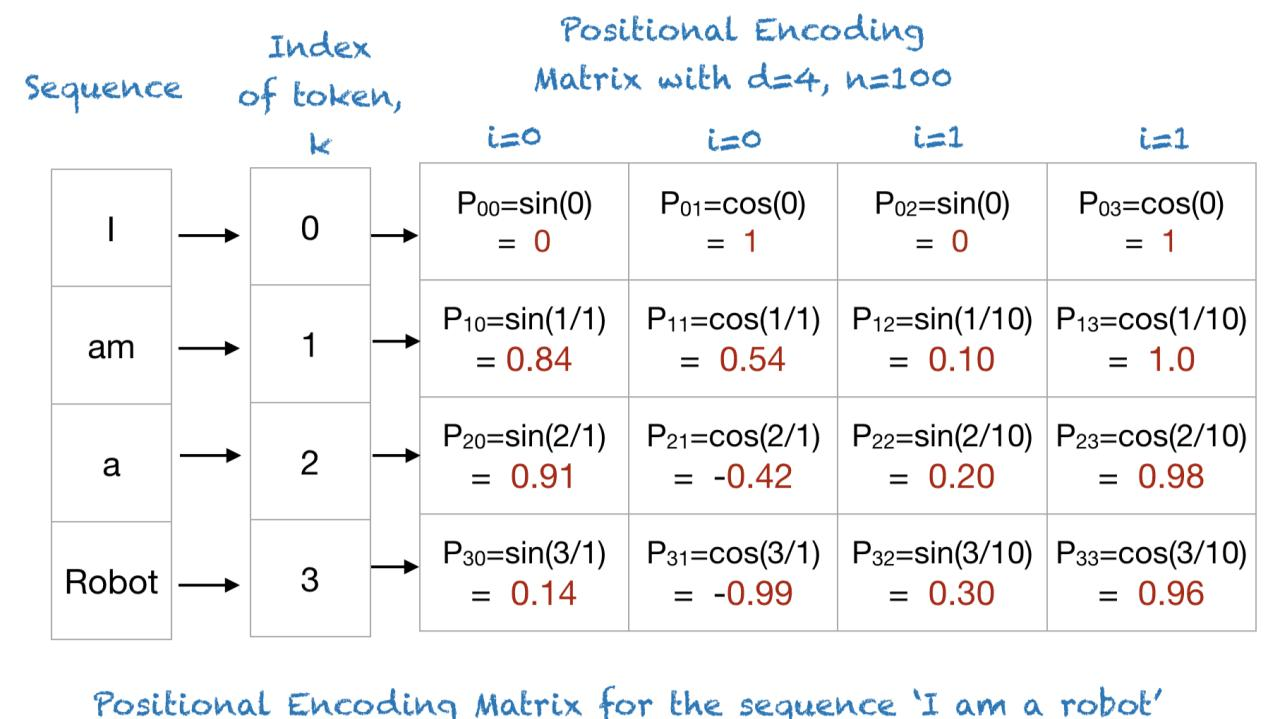

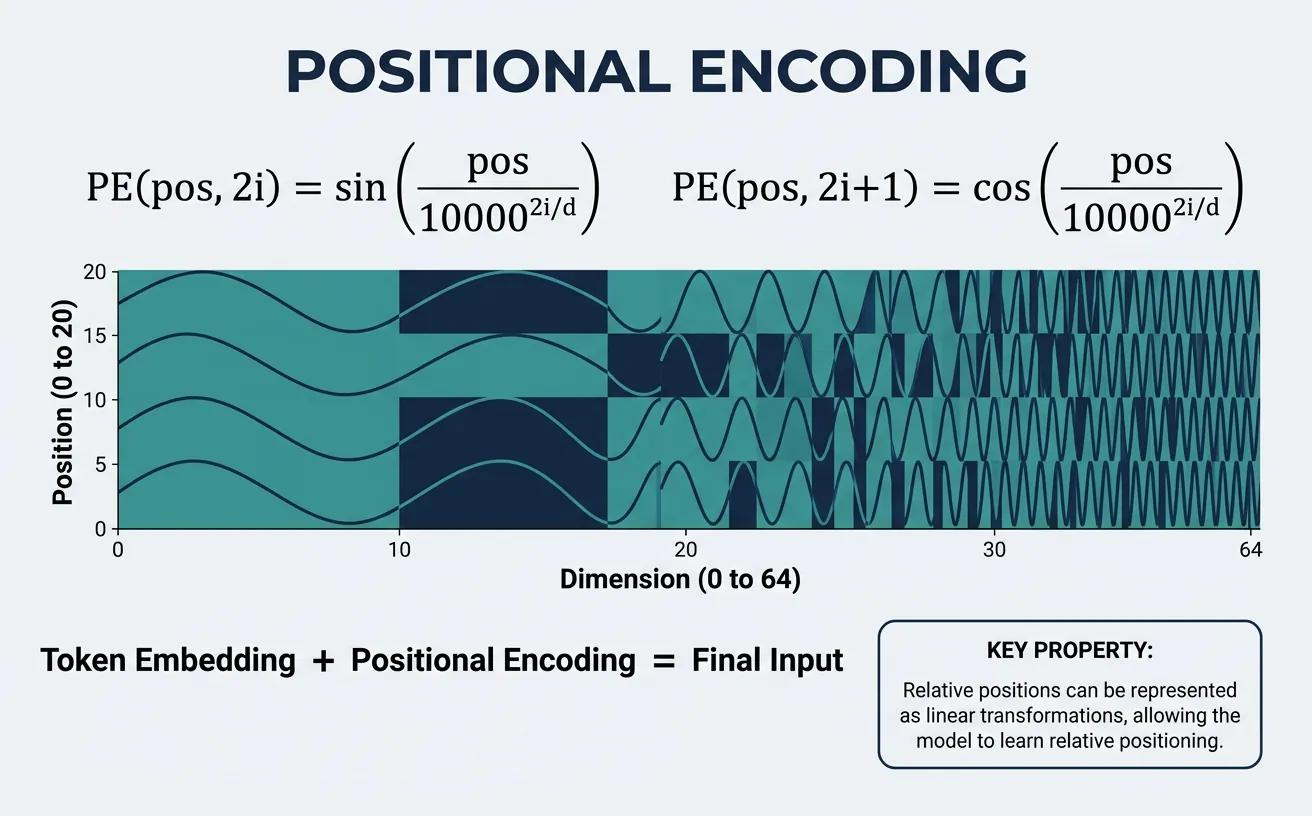

The original Transformer uses sine and cosine functions to generate positional encodings.

For position \(pos\) and dimension \(i\):

$$
PE_{(pos,2i)}
=
\sin
\left(
\frac{pos}{10000^{2i/d_{\text{model}}}}
\right)
$$

and:

$$
PE_{(pos,2i+1)}
=
\cos
\left(
\frac{pos}{10000^{2i/d_{\text{model}}}}
\right)
$$

where:

- \(pos\) = position of the token
- \(i\) = embedding dimension index
- \(d_{\text{model}}\) = model embedding dimension

The resulting positional encoding has the same dimensionality as the token embedding.

Therefore:

$$
E,P \in \mathbb{R}^{d_{\text{model}}}
$$

and they can be added:

$$
X = E + P
$$

---

## 5.6 Intuition Behind Sinusoidal Encoding

Different positions produce different patterns of sine and cosine values.

Conceptually:

```text
Position 0 → [sin/cos pattern]
Position 1 → [different pattern]
Position 2 → [different pattern]
Position 3 → [different pattern]
       ...
```

Therefore, each position gets a distinctive numerical representation.



---

## 5.7 Why Add Position to Embeddings?

Suppose:

```text
"The cat sat"
```

The token embedding represents semantic information:

```text
"The" → token representation
"cat" → token representation
"sat" → token representation
```

But the model also needs:

```text
"The" → position 1
"cat" → position 2
"sat" → position 3
```

Combining them gives:

$$
\text{Transformer Input}
=
\text{Token Embedding}
+
\text{Positional Encoding}
$$

This allows the model to use both **token identity** and **position**.

---

## 5.8 Important Mental Model

Think of the two components as answering different questions:

```text
Token Embedding
       ↓
"What is this token?"

Positional Encoding
       ↓
"Where is this token?"

        ↓
      Add

        ↓
"What token is this,
 and where does it occur?"
```

This is the key intuition behind positional information.

---

## 5.9 Position Is Important for Meaning

Compare:

```text
"The dog chased the cat."
```

with:

```text
"The cat chased the dog."
```

The same words are involved, but the roles change because their positions change.

Therefore:

> **Word identity alone is insufficient for understanding a sequence.**

A Transformer needs both **content** and **position**.

---

## 5.10 Important Distinction

Do not confuse:

### Token Embedding

Represents information associated with the token.

$$
E_{\text{token}}
$$

### Positional Encoding

Represents information associated with the token's position.

$$
P_{\text{position}}
$$

### Combined Representation

$$
X = E_{\text{token}} + P_{\text{position}}
$$

This combined representation is then passed into the Transformer.

---

## 5.11 Why This Matters in the Transformer Architecture

The overall flow becomes:

```text
Text
 ↓
Tokenization
 ↓
Token IDs
 ↓
Token Embeddings
 ↓
+ Positional Information
 ↓
Transformer Encoder / Decoder
 ↓
Contextual Representations
```

For the encoder:

```text
Token Embeddings
       +
Positional Information
       ↓
Multi-Head Self-Attention
       ↓
FFN
       ↓
Encoder Output
```

For the decoder, positional information is also part of the decoder's input representations.

---

# Interview Perspective 🎯

### Why is positional information required in Transformers?

> Transformers do not use recurrence, so token order is not inherently represented by the computation. Positional information is therefore added to token representations so that the model can distinguish tokens based on their positions in the sequence.

### How was positional information represented in the original Transformer?

> The original Transformer used sinusoidal positional encodings based on sine and cosine functions, which were added to the token embeddings.

### Why can't we use only token embeddings?

Because:

```text
"The dog bites the man"
```

and:

```text
"The man bites the dog"
```

contain the same tokens but have different meanings due to their order.

---

# What You Should Remember

1. **Attention does not inherently provide token order.**
2. Transformers therefore require **positional information**.
3. Token embeddings represent **what the token is**.
4. Positional encoding represents **where the token occurs**.
5. The original Transformer used **sinusoidal positional encodings**.
6. The combined representation is:

$$
X = E + P
$$

7. Sinusoidal positional encoding uses:

$$
PE_{(pos,2i)}
=
\sin
\left(
\frac{pos}{10000^{2i/d_{\text{model}}}}
\right)
$$

$$
PE_{(pos,2i+1)}
=
\cos
\left(
\frac{pos}{10000^{2i/d_{\text{model}}}}
\right)
$$

8. The core intuition is:

```text
Token Embedding → WHAT
Positional Encoding → WHERE

WHAT + WHERE
     ↓
Transformer
```

----